In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [53]:
df = pd.read_csv("ram.csv")

In [54]:
df


,ArrivalRate,device_write,cpus,memory,cpuLoad,size,Throughput,ResponseTime
0,10,10mb,0.5,256m,0,0,0.0,4.1
1,10,10mb,0.5,256m,100,0,0.0,4.2
2,10,10mb,0.5,256m,1000,0,0.0,4.1
3,10,10mb,0.5,256m,0,250,0.0,4.1
4,10,10mb,0.5,256m,100,250,0.0,4.2
...,...,...,...,...,...,...,...,...
1210,100,5mb,2.0,1g,100,250,7.9,75102.4
1211,100,5mb,2.0,1g,1000,250,8.0,76861.0
1212,100,5mb,2.0,1g,0,1000,7.9,50344.7
1213,100,5mb,2.0,1g,100,1000,8.0,52607.4


In [55]:
def strip_suf(x):
    if isinstance(x, str):
        if x.endswith("mb"):
            return int(x[:-2])
        if x.endswith("m"):
            return int(x[:-1])
        if x.endswith("g"):
            return int(x[:-1]) * 1024
    return float(x)

df["device_write"] = df["device_write"].apply(strip_suf)
df["memory"] = df["memory"].apply(strip_suf) 

In [56]:
df

,ArrivalRate,device_write,cpus,memory,cpuLoad,size,Throughput,ResponseTime
0,10,10,0.5,256,0,0,0.0,4.1
1,10,10,0.5,256,100,0,0.0,4.2
2,10,10,0.5,256,1000,0,0.0,4.1
3,10,10,0.5,256,0,250,0.0,4.1
4,10,10,0.5,256,100,250,0.0,4.2
...,...,...,...,...,...,...,...,...
1210,100,5,2.0,1024,100,250,7.9,75102.4
1211,100,5,2.0,1024,1000,250,8.0,76861.0
1212,100,5,2.0,1024,0,1000,7.9,50344.7
1213,100,5,2.0,1024,100,1000,8.0,52607.4


In [57]:
df[df["Throughput"] == 0.0].count()

ArrivalRate     351
device_write    351
cpus            351
memory          351
cpuLoad         351
size            351
Throughput      351
ResponseTime    351
dtype: int64

In [58]:
def filter(df, arr=None, dw=None, cpus=None, mem=None, cpuld=None, sz=None,tput=None,resp=None):
    if arr is not None:
        df = df[df["ArrivalRate"] == arr]
    if dw is not None:
        df = df[df["device_write"] == dw]
    if cpus is not None:
        df = df[df["cpus"] == cpus]
    if mem is not None:
        df = df[df["memory"] == mem]
    if cpuld is not None:
        df = df[df["cpuLoad"] == cpuld]
    if sz is not None:
        df = df[df["size"] == sz]
    if tput is not None:
        df = df[df["Throughput"] == tput]
    if resp is not None:
        df = df[df["ResponseTime"] == resp]
    return df

In [59]:
def plot(colx, coly, data, title, name = None, split_on = None, ):
    plt.figure()
    if isinstance(coly, str):
        coly = [coly]
    if(split_on):
        for val in data[split_on].unique():
            dt = data[data[split_on] == val]
            dt = dt.sort_values(by=colx)
            for c in coly:
                plt.plot(dt[colx], dt[c], label=f"{c}, {split_on}={val}")
                
        plt.legend()
    else:
        data = data.sort_values(by=colx)
        for c in coly:
            plt.plot(data[c], data[coly], label=f"c")
    plt.xlabel(colx)
    plt.ylabel(coly)
    plt.title(title)
    plt.grid(True)
    if(name):
        plt.savefig(f"plots/{name}.png")
    plt.show()
    plt.close()




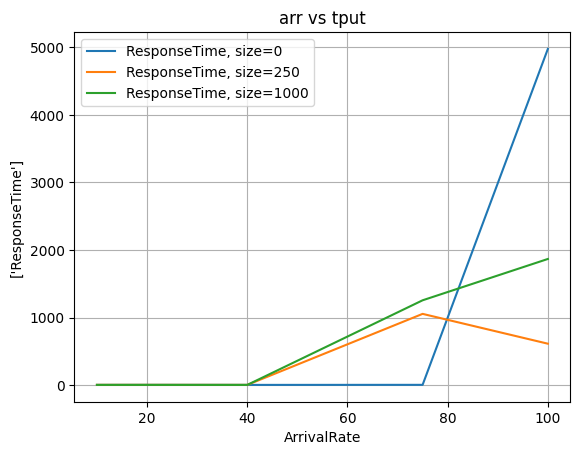

In [70]:
plot("ArrivalRate", ["ResponseTime"], filter(df,dw=20,cpus=2,mem=1024,cpuld=0), "arr vs tput", split_on="size")

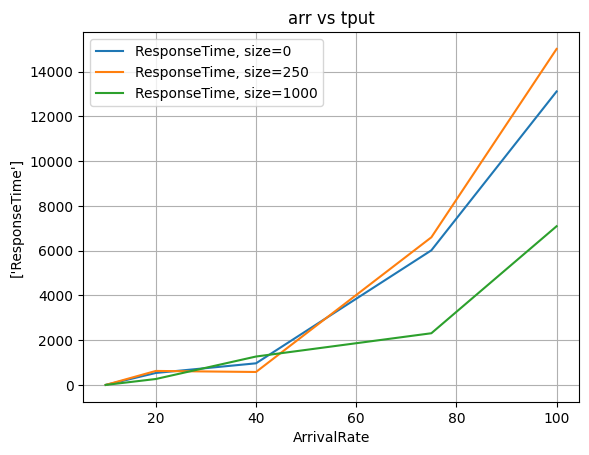

In [63]:
plot("ArrivalRate", "ResponseTime", filter(df,dw=20,cpus=2,mem=256,cpuld=0), "arr vs tput", split_on="size")